In [1]:
import numpy as np
import xtrack as xt
import matplotlib.pyplot as plt
import re
import sys
helpers_path = f'../' # specify the path for helper functions file
sys.path.insert(0, helpers_path)
from helpers_for_imperfections_model import find_elements

In [2]:
### Comments from Jorg (on the 11f/1101f files in lattices/reference_lattice/_fromJorg; this notebook now uses acc-models-lep3 v12)
# You can find Z and H files for LEP3. So far I worked with 11f, the
# latest is 1101f (11.0.1). Not fully sure what the difference is. In case
# of doubt start with 11f.

# LEP3 has only 2 experiments (in the positions of ATLAS and CMS).

# Note that the arc bends are combined function magnets. Although the K1
# does not look large, integrated over a 3 bends between 2 quads, K1L is
# sizeable. That could be interesting wrt dipole alignment tolerances.
# Surely an interesting point to investigate the tolerances for such
# combined fct bends.

In [3]:
line_file = 'lattices/reference_lattice/lep3_z.json' # from acc-models-lep3-v12/lattices/z/lep3_z.json
env = xt.Environment.from_json(line_file)
line = env.lines['lep3_p_ring']
line.cycle(name_first_element='rf800.0', inplace=True) # start at the rf cavity, as the lines of notebooks 02-04 (v12 starts at the IP)
# v12 comes without BPMs and orbit/optics correctors: they are installed below. Repeated elements are named <family>.<n>

# gamma to kinetic energy in GeV # same as FCC-ee?
gamma = line.particle_ref.gamma0[0]
mass0_gev = line.particle_ref.mass0 * 1e-9
kinetic_energy = float((gamma - 1) * mass0_gev)
print(f'kinetic_energy = ',kinetic_energy, ' GeV')
tt = line.get_table()
tt.keys()

Loading line from dict:   0%|          | 0/10700 [00:00<?, ?it/s]

kinetic_energy =  45.599489001049314  GeV


dict_keys(['s', 'element_type', 'name', 'isthick', 'isreplica', 'parent_name', 'parent_type', 'prototype', 'base_prototype', 'iscollective', 's_start', 's_center', 's_end', 'env_name'])

/Users/prebibaj/miniforge3/envs/fcc-2026/lib/python3.13/site-packages/xplt/hooks.py:31: RuntimeWarning: Failed to register formatters with pint: No module named 'pint'
  warnings.warn(f"Failed to register formatters with pint: {e}", RuntimeWarning)


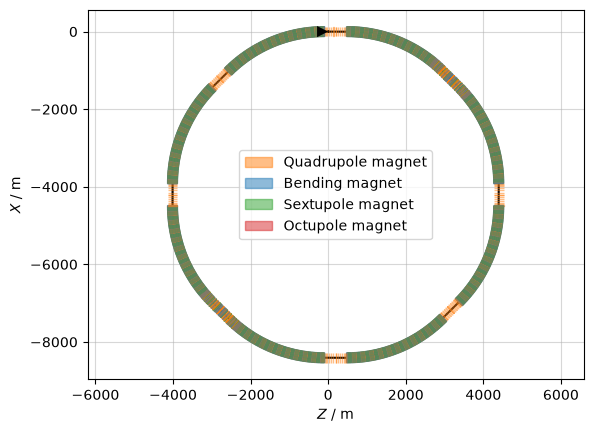

In [4]:
# check survey and plot using xplt
sv = line.survey()
sv.plot()

### Matching tune

Number of quads dependent on kqf1 784
Number of quads dependent on kqd1 876


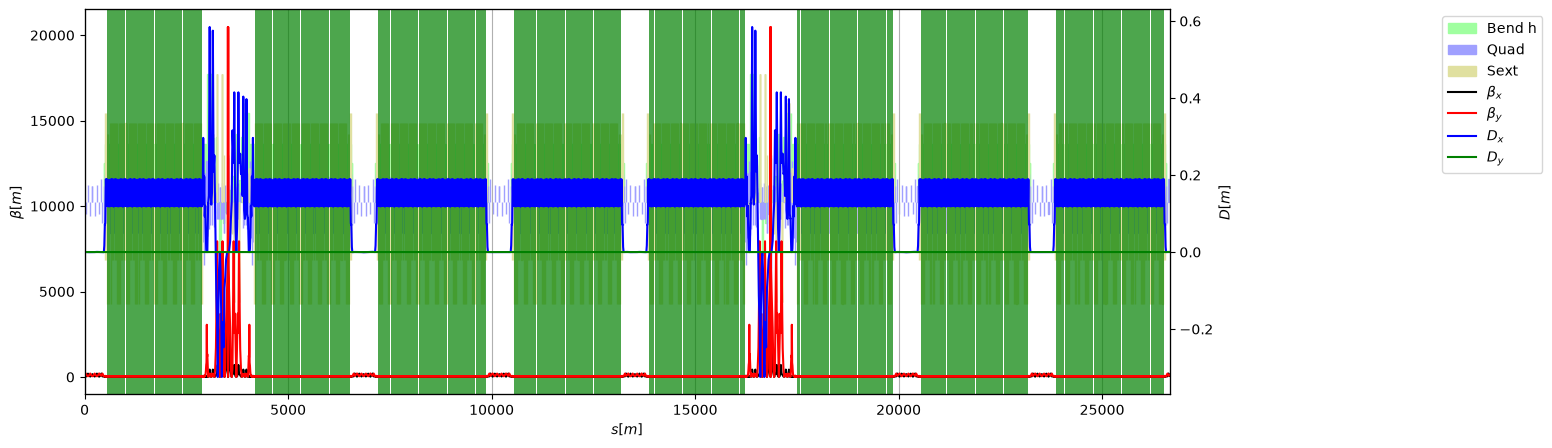

In [5]:
# Get all variables
#print(line.vars.get_independent_vars())
ttvar = line.vars.get_table()

var1list = list(line.vars['kqf1']._find_dependant_targets())[1::]
dependent_on_kqf1 = []
for el in var1list:
    if 'k1' in str(el) and str(el).split("'")[1] in tt.name: # skip the parent elements of the environment (not in the line)
        dependent_on_kqf1.append(str(str(el).split("'")[1]))
print('Number of quads dependent on kqf1', len(dependent_on_kqf1))

var1list = list(line.vars['kqd1']._find_dependant_targets())[1::]
dependent_on_kqd1 = []
for el in var1list:
    if 'k1' in str(el) and str(el).split("'")[1] in tt.name: # skip the parent elements of the environment (not in the line)
        dependent_on_kqd1.append(str(str(el).split("'")[1]))
print('Number of quads dependent on kqd1', len(dependent_on_kqd1))

tw = line.twiss()

f, ax = plt.subplots(1,1,figsize=(14,5))
tw.plot(ax=ax)
#ax.set_xlim(8000, 12000)
#ax.set_xlim(5000-200, 5000+200)
for q in dependent_on_kqf1:
    ax.axvline(x=tt.s[tt.name==q], color='green', linestyle='-', lw=0.5)
# for q in dependent_on_kqd1:
#    ax.axvline(x=tt.s[tt.name==q], color='red', linestyle='-', lw=0.5)


# opt_tune = line.match(
#     method='6d',
#     vary=[xt.VaryList(['kqf1', 'kqd1'], step=1e-8, tag='quad'),
#         ],
#     targets=[xt.TargetSet(qx=195.1662643101125, qy=87.2107959626699, tol=1e-5, tag='tune'),
#         ])

### Matching chroma

In [6]:
# Add chroma knobs, a la FCC-ee (on the arc sextupole families sf1a-sf4a, sd1a-sd4a)
line.vars['sf.k2n.chroma.knob'] = 1
line.vars['sd.k2n.chroma.knob'] = 1
for ii in tt.rows['sf[1-4]a.*'].name:
    if '_aper' not in ii:
        line.element_refs[ii].k2 = line.vars['sf.k2n.chroma.knob']*line.element_refs[ii].k2._expr
for ii in tt.rows['sd[1-4]a.*'].name:
    if '_aper' not in ii:
        line.element_refs[ii].k2 = line.vars['sd.k2n.chroma.knob']*line.element_refs[ii].k2._expr

In [7]:
tw0 = line.twiss()
print(tw0.qx, tw0.qy)
print(tw0.dqx, tw0.dqy)
print(tw0.rows['ip.*'].cols['betx bety'])

175.11700000066347 121.1369998590369
2.0017065584992926 2.003101053359961
TwissTable: 4 rows, 3 cols
name          betx          bety
ip.1     0.0996401   0.000503722
ip.2     0.0996401   0.000503722
ip.3     0.0996401   0.000503722
ip.0     0.0996401   0.000503722


In [8]:
# opt_chroma = line.match(
#     method='6d',
#     vary=[xt.VaryList(['sf.k2n.chroma.knob', 'sd.k2n.chroma.knob',], step=1e-3, tag='sext'),
#         ],
#     targets=[xt.TargetSet(dqx=5, dqy=4, tol=1e-2, tag='chrom'),
#         ])
# # tw0 = line.twiss()
# # print(tw0.qx, tw0.qy)
# # print(tw0.dqx, tw0.dqy)
# # print(tw0.rows['ip.*'].cols['betx bety'])

# Twiss

In [9]:
#line.twiss_default['method'] = '4d' # if no RF present, default is '6d
#line.twiss_default['group_compound_elements'] = True # to hide group "compound" elements
#line.twiss_default
tw = line.twiss()
print('Tune x, y = ', tw.qx, tw.qy)

Tune x, y =  175.11700000066347 121.1369998590369


(4800.0, 5200.0)

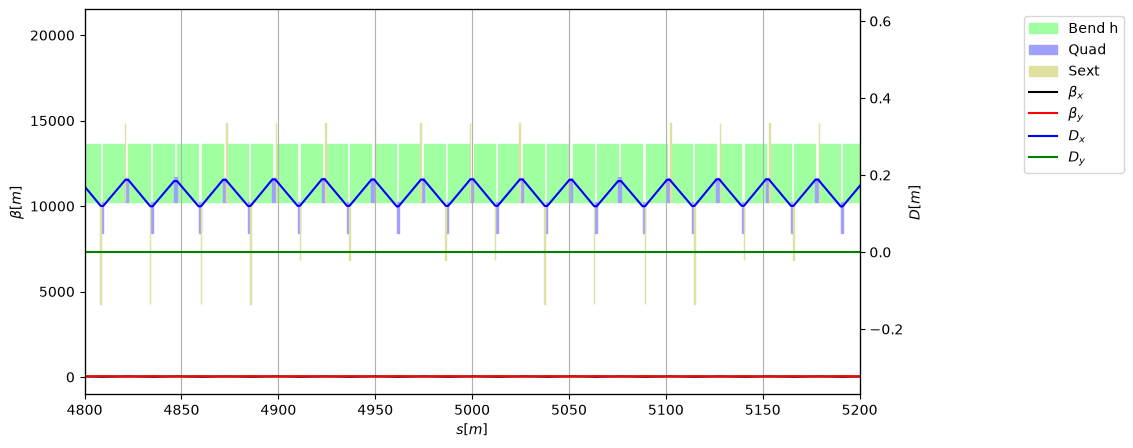

In [10]:
f, ax = plt.subplots(1,1,figsize=(10,5))
tw.plot(ax=ax)
#ax.set_xlim(8000, 12000)
ax.set_xlim(5000-200, 5000+200)
#for qa in ttqa.name:
#    if '.2' in qa:
#        print(qa)
#        ax.axvline(x=ttqa.s[ttqa.name==qa], color='black', linestyle='--', lw=2)

# Install markers at the IR boundaries

In [11]:
line2 = line.copy()

In [12]:
# Find IPs
C    = line2.get_length()
tt   = line2.get_table()
tta  = line2.get_table(attr=True)
ips = tt.rows['.*ip.*']
ip_names = ips.name[0::2]
ip_s = ips.s[0::2]
print(ip_s)
#ip_s = np.array([9994.59293139, 23320.76038856])   # or from your tt.rows[...] slice
d    = ip_s[1] - ip_s[0]
print(f'C          = {C:.6f} m')
print(f'IP spacing = {d:.6f} m')
print(f'C/2        = {C/2:.6f} m   ->  mismatch {d - C/2:+.6f} m')

[ 3524.49362295 16853.99354263]
C          = 26658.999839 m
IP spacing = 13329.499920 m
C/2        = 13329.499920 m   ->  mismatch +0.000000 m


In [13]:
# Find symmetry points, numbered such that the two IPs are IR3 and IR7 (as in lattice_markers.py), wherever the line starts
s_points = np.array([(ip_s[0] + (k - 2) * C / 8) % C for k in range(8)])
print('eight symmetry points:')
for j, sp in enumerate(s_points):
    print(f'  IR{j+1}:  s = {sp:11.3f} m')


eight symmetry points:
  IR1:  s =   23518.744 m
  IR2:  s =     192.119 m
  IR3:  s =    3524.494 m
  IR4:  s =    6856.869 m
  IR5:  s =   10189.244 m
  IR6:  s =   13521.619 m
  IR7:  s =   16853.994 m
  IR8:  s =   20186.369 m


In [14]:
# Find boundaries between straights and arcs
n_el   = len(line2.element_names)
s_el   = tta.s[:n_el]
len_el = tta.length[:n_el]
k0l_el = tta.k0l[:n_el]
type_el = tta.element_type[:n_el]
is_bend = (type_el == 'Bend') & (np.abs(k0l_el) > 1e-12) # arc-type (combined-function) dipoles only: the RBends of the final focus
                                                          # are ignored, so that the IRs extend up to the first DS dipole, as the TRs
print(f'{is_bend.sum()} arc-type bending elements found')      # sanity check
s_bend_in  = s_el[is_bend]
s_bend_out = s_el[is_bend] + len_el[is_bend]
def bend_free_extent(s_c):
    """Distance from s_c to the first bend downstream / upstream."""
    d_fwd = (s_bend_in  - s_c) % C
    d_bwd = (s_c - s_bend_out) % C
    return d_bwd.min(), d_fwd.min()
MARGIN = 0.0    # m; positive value eats into the arc (dispersion suppressor),
                # negative value keeps the boundary strictly inside the straight
boundaries = []
print('\nIR extents:')
for i, s_c in enumerate(s_points, start=1):
    back, fwd = bend_free_extent(s_c)
    s_start = (s_c - back - MARGIN) % C
    s_end   = (s_c + fwd  + MARGIN) % C
    boundaries.append((f'ir{i}_start', s_start))
    boundaries.append((f'ir{i}_end',   s_end))
    print(f'  IR{i}:  s = {s_c:10.2f}   straight = {back+fwd:8.2f} m '
          f'({back:7.2f} back / {fwd:7.2f} fwd)')

1672 arc-type bending elements found

IR extents:
  IR1:  s =   23518.74   straight =   559.34 m ( 279.64 back /  279.70 fwd)
  IR2:  s =     192.12   straight =   559.34 m ( 279.64 back /  279.70 fwd)
  IR3:  s =    3524.49   straight =  1060.55 m ( 530.24 back /  530.31 fwd)
  IR4:  s =    6856.87   straight =   559.34 m ( 279.64 back /  279.70 fwd)
  IR5:  s =   10189.24   straight =   559.34 m ( 279.64 back /  279.70 fwd)
  IR6:  s =   13521.62   straight =   559.34 m ( 279.64 back /  279.70 fwd)
  IR7:  s =   16853.99   straight =  1060.55 m ( 530.24 back /  530.31 fwd)
  IR8:  s =   20186.37   straight =   559.34 m ( 279.64 back /  279.70 fwd)


In [15]:
# Install markers at the boundaries
def nearest_element_index(s_target):
    i = int(np.searchsorted(s_el, s_target))
    i = int(np.clip(i, 1, n_el - 1))
    if abs(s_el[i] - s_target) > abs(s_el[i-1] - s_target):
        i -= 1
    return i

resolved = [(name, nearest_element_index(s)) for name, s in boundaries]

for name, idx in sorted(resolved, key=lambda x: -x[1]):
    line2.insert_element(index=idx, element=xt.Marker(), name=name)

print(line2.get_table().rows[r'ir\d+_(start|end)'])

LineTable: 16 rows, 14 cols
name                  s element_type isthick isreplica parent_name parent_type prototype ...
ir2_end         471.821 Marker         False     False None        None        None     
ir3_start       2994.25 Marker         False     False None        None        None     
ir3_end          4054.8 Marker         False     False None        None        None     
ir4_start       6577.23 Marker         False     False None        None        None     
ir4_end         7136.57 Marker         False     False None        None        None     
ir5_start        9909.6 Marker         False     False None        None        None     
ir5_end         10468.9 Marker         False     False None        None        None     
ir6_start         13242 Marker         False     False None        None        None     
ir6_end         13801.3 Marker         False     False None        None        None     
ir7_start       16323.7 Marker         False     False None        None       

/Users/prebibaj/miniforge3/envs/fcc-2026/lib/python3.13/site-packages/xtrack/line.py:4406: FutureWarning: Line.insert_element is deprecated. Use Line.insert instead. This deprecation is part of the interface cleanup in view of the 1.0 release.
  warn('Line.insert_element is deprecated. Use Line.insert instead.'


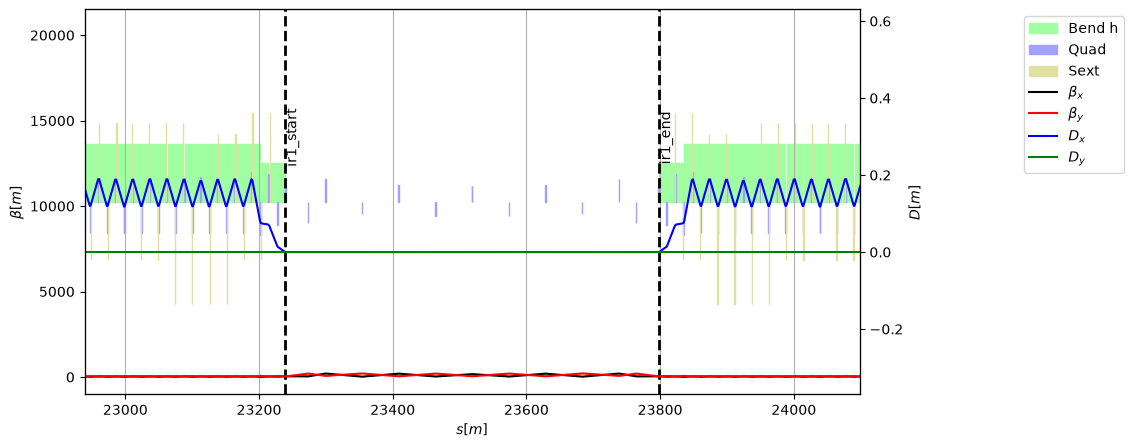

In [16]:
tt = line2.get_table()
tw = line2.twiss()
f, ax = plt.subplots(1,1,figsize=(10,5))
tw.plot(ax=ax)
xlim1, xlim2 = tt['s', 'ir1_start'] - 300, tt['s', 'ir1_end'] + 300 # a technical region (no dipoles)
#xlim1, xlim2 = tt['s', 'ir3_start'] - 300, tt['s', 'ir3_end'] + 300 # an interaction region
#xlim1, xlim2 = 0, 27000
ax.set_xlim(xlim1, xlim2)
for irbounary, irname in zip(tt.rows['ir.*'].s, tt.rows['ir.*'].name):
    ax.axvline(x=irbounary, color='black', linestyle='--', lw=2)
    if xlim1 < irbounary < xlim2:
        ax.text(irbounary+0.1, 0.5, f'{irname}', rotation=90, verticalalignment='center', fontsize=10)

In [17]:
# Hardcoded for now; to be improved later
markers_per_arc = [
    ('ir8_end', 'ir1_start'),
    ('ir1_end', 'ir2_start'),
    ('ir2_end', 'ir3_start'),
    ('ir3_end', 'ir4_start'),
    ('ir4_end', 'ir5_start'),
    ('ir5_end', 'ir6_start'),
    ('ir6_end', 'ir7_start'),
    ('ir7_end', 'ir8_start'),
]
markers_per_tr = [
    ('ir1_start', 'ir1_end'),
    ('ir2_start', 'ir2_end'),
    ('ir4_start', 'ir4_end'),
    ('ir5_start', 'ir5_end'),
    ('ir6_start', 'ir6_end'),
    ('ir8_start', 'ir8_end'),
]
markers_per_ff = [
    ('ir3_start', 'ir3_end'),
    ('ir7_start', 'ir7_end'),
]

all_arc_bends = find_elements(tt, marker_pairs = markers_per_arc)
all_arc_bends = all_arc_bends.rows[(all_arc_bends.element_type == 'Bend') | (all_arc_bends.element_type == 'RBend')]
all_arc_quads = find_elements(tt, marker_pairs = markers_per_arc, element_type = 'Quadrupole')
all_arc_sexts = find_elements(tt, marker_pairs = markers_per_arc, element_type = 'Sextupole')

all_tr_bends = find_elements(tt, marker_pairs = markers_per_tr, element_type='Bend')
#all_tr_bends = all_tr_bends.rows[(all_arc_bends.element_type == 'Bend') | (all_arc_bends.element_type == 'RBend')]
all_tr_quads = find_elements(tt, marker_pairs = markers_per_tr, element_type = 'Quadrupole')
all_tr_sexts = find_elements(tt, marker_pairs = markers_per_tr, element_type = 'Sextupole')

all_ff_bends = find_elements(tt, marker_pairs = markers_per_ff)
all_ff_bends = all_ff_bends.rows[(all_ff_bends.element_type == 'Bend') | (all_ff_bends.element_type == 'RBend')]
all_ff_quads_but_fd = find_elements(tt, marker_pairs = markers_per_ff, element_type = 'Quadrupole', except_pattern='q[f|d][0|1][a|b|c][r|l]')
all_fd_quads = find_elements(tt, pattern='q[f|d][0|1][a|b|c][r|l]',element_type = 'Quadrupole')
all_ff_sexts = find_elements(tt, marker_pairs = markers_per_ff, element_type = 'Sextupole')

print(f'Found in arcs: {len(all_arc_bends.name)} dipoles, {len(all_arc_quads.name)} quads, {len(all_arc_sexts.name)} sextupoles.')
print(f'Found in technical regions: {len(all_tr_bends.name)} dipoles, {len(all_tr_quads.name)} quads, {len(all_tr_sexts.name)} sextupoles.')
print(f'Found in final focusing: {len(all_ff_bends.name)} dipoles, {len(all_fd_quads.name)} FD quads and {len(all_ff_quads_but_fd.name)} other quads, {len(all_ff_sexts.name)} sextupoles.')

Found in arcs: 1672 dipoles, 1748 quads, 1440 sextupoles.
Found in technical regions: 0 dipoles, 84 quads, 0 sextupoles.
Found in final focusing: 70 dipoles, 20 FD quads and 148 other quads, 88 sextupoles.


/Users/prebibaj/cernbox/EPFL/15_handover/FCCee_Project_2026/LEP3_Z_V12_imperfections_model/../helpers_for_imperfections_model.py:90: UserWarning: Warning: No elements matched.
  warnings.warn("Warning: No elements matched.")


# Group the slices of the same magnet
The BPMs, orbit correctors and optics trims are installed once per magnet, not once per slice.


In [18]:
def group_magnet_slices(tt, element_names, tol=1e-6):
    """
    Group consecutive slices of the same magnet: same family name (name without '.<n>') and touching (s_end = next s_start).
    Returns a list of magnets, each one being the list of its slice names (in line order). Same as in notebook 02.
    """
    tt_sel = tt.rows[np.isin(tt.name, element_names)]
    family = lambda name: re.sub(r'\.\d+$', '', name)
    magnets = []
    for name, s_start, s_end in zip(tt_sel.name, tt_sel.s_start, tt_sel.s_end):
        if magnets and family(name) == family(magnets[-1][-1]) and abs(s_start - previous_s_end) < tol:
            magnets[-1].append(name)
        else:
            magnets.append([name])
        previous_s_end = s_end
    return magnets


# Install BPMs (markers) at every quadrupole (straights and IRs)

In [19]:
env = line2.env
tt = line2.get_table()
all_quads = list(all_arc_quads.name) + list(all_tr_quads.name) + list(all_ff_quads_but_fd.name) + list(all_fd_quads.name)
all_quad_magnets = group_magnet_slices(tt, all_quads) # one BPM per magnet, at the entrance of its first slice
print(f'{len(all_quads)} quadrupole slices -> {len(all_quad_magnets)} magnets')
inserts = []
for magnet in all_quad_magnets:
    nm = magnet[0]
    if 'qd0b' in nm or 'qd0c' in nm or 'qf1b' in nm:
        print(f'Skipping BPM insertion at {nm} (QD0 quadrupole)')
        continue
    bpm_name = f'bpm_{nm}'
    env.new(bpm_name, xt.Marker)
    s_quad = tt['s_start', nm]
    inserts.append(env.place(bpm_name, at=s_quad))
print(f'Inserted {len(inserts)} BPMs at quadrupoles')
line2.insert(inserts)
tt = line2.get_table()   # refresh after insertion


2000 quadrupole slices -> 1894 magnets
Skipping BPM insertion at qf1bl.0 (QD0 quadrupole)
Skipping BPM insertion at qd0cl.0 (QD0 quadrupole)
Skipping BPM insertion at qd0bl.0 (QD0 quadrupole)
Skipping BPM insertion at qd0br.1 (QD0 quadrupole)
Skipping BPM insertion at qd0cr.1 (QD0 quadrupole)
Skipping BPM insertion at qf1br.1 (QD0 quadrupole)
Skipping BPM insertion at qf1bl.1 (QD0 quadrupole)
Skipping BPM insertion at qd0cl.1 (QD0 quadrupole)
Skipping BPM insertion at qd0bl.1 (QD0 quadrupole)
Skipping BPM insertion at qd0br.0 (QD0 quadrupole)
Skipping BPM insertion at qd0cr.0 (QD0 quadrupole)
Skipping BPM insertion at qf1br.0 (QD0 quadrupole)
Inserted 1882 BPMs at quadrupoles


Slicing line:   0%|          | 0/10474 [00:00<?, ?it/s]

# Install hcorr and vcorr at every quadrupole

In [20]:
qf_quads = []
qd_quads = []
for magnet in all_quad_magnets: # one H and one V corrector per magnet, at the entrance of its first slice (named after it)
    nm = magnet[0]
    k1 = line2[nm].k1
    if k1 > 0:
        qf_quads.append(nm)
    else:
        qd_quads.append(nm)
print(f'{len(qf_quads)} QF quads  ->  horizontal correctors')
print(f'{len(qd_quads)} QD quads  ->  vertical correctors')

env = line2.env
tt = line2.get_table()

inserts = []
hcor_names = []
vcor_names = []

for nm in qf_quads+qd_quads:
    corr_name = f'hcor_{nm}'
    if corr_name in line2.element_dict:
        continue
    line2.vars[f'knl_{nm}'] = 0.0
    env.new(corr_name, xt.Multipole, knl=[0.])
    inserts.append(env.place(corr_name, at=tt['s_start', nm]))
    hcor_names.append(corr_name)

for nm in qd_quads+qf_quads:
    corr_name = f'vcor_{nm}'
    if corr_name in line2.element_dict:
        continue
    line2.vars[f'ksl_{nm}'] = 0.0
    env.new(corr_name, xt.Multipole, ksl=[0.])
    inserts.append(env.place(corr_name, at=tt['s_start', nm]))
    vcor_names.append(corr_name)

line2.insert(inserts)

for nm in qf_quads:
    line2.element_refs[f'hcor_{nm}'].knl[0] = line2.vars[f'knl_{nm}']

for nm in qd_quads:
    line2.element_refs[f'ksl_{nm}'.replace('ksl_', 'vcor_')].ksl[0] = line2.vars[f'ksl_{nm}']

tt = line2.get_table()
tthcor = tt.rows['hcor_.*']
ttvcor = tt.rows['vcor_.*']
print(f'installed {len(tthcor)} H correctors, {len(ttvcor)} V correctors')

946 QF quads  ->  horizontal correctors
948 QD quads  ->  vertical correctors


Slicing line:   0%|          | 0/12356 [00:00<?, ?it/s]

installed 1894 H correctors, 1894 V correctors


In [21]:
line2.to_json('lattices/reference_lattice/LEP3_Z_v12_wMarkers_wBPMs_wCorr.json')

# Install optics correctors (trims) at every quadrupole and sextupole
LEP3 equivalent of the trims installed in `FCCee_LCC_Z_V107p0p1_imperfections_model/01_install_correctors.py`, needed for the response matrices and the optics correction.
- Normal quadrupole trims (`knl1_*`) at all normal (powered) quadrupoles, skew quadrupole trims (`ksl1_*`) at all normal (powered) sextupoles.
- One knob per magnet: the slices of the same magnet (e.g. the two `qd1am` halves at a cell boundary, `qx2l` around `imag4`, `qf10s` around `scenter`,
  the 4 slices of `sfx1l` or `scrabl`) share the knob, split according to their length, as for the imperfections (notebook 02).
  The knob is named after the first slice, e.g. `knl1_qd1am.15`.
- The line already starts at `rf800.0` (cycled at the beginning of the notebook), as the lines with imperfections (notebook 02).
  The response matrices are built on this line (`helpers_for_RM_generation`), so the phases need no re-referencing in the corrections.

The saved line is the reference line of the LEP3 model: it is the input of notebook 02 and of the scripts in `helpers_for_RM_generation`.


In [22]:
line2.configure_radiation(model=None, model_beamstrahlung=None)
tt = line2.get_table() # refresh


In [23]:
def add_correctors_per_magnet(line, magnets, type='normal', order=1, switch_name=None):
    """
    Same as helpers_for_imperfections_model.add_correctors, but with one knob per magnet (named after its first slice),
    shared by all its slices in proportion to their length, so that the knob is the integrated strength of the magnet.
    Returns the list of knob names.
    """
    if switch_name is not None:
        line.vars[switch_name] = 1

    if type == 'normal':
        attr = 'knl'
    elif type == 'skew':
        attr = 'ksl'
    else:
        raise ValueError(f"Unsupported corrector type '{type}'. Supported types are 'normal' and 'skew'.")

    knob_names = []
    for slices in magnets:
        knob_name = attr + str(order) + '_' + slices[0]
        line.vars[knob_name] = 0
        knob_names.append(knob_name)
        total_length = sum(line[name].length for name in slices)
        for name in slices:
            current = getattr(line.element_refs[name], attr)[order]._expr # <-- Take current expression
            if current is None: # <-- to handle the case in which the attribute has no expression, just a value
                current = getattr(line.element_refs[name], attr)[order]._value
            increment = line.vars[knob_name] * (line[name].length / total_length)
            getattr(line.element_refs[name], attr)[order] = (current + increment * line.vars[switch_name]) if switch_name is not None else (current + increment)
    return knob_names

In [24]:
# Normal (powered) quadrupoles and sextupoles
ttquad = tt.rows[tt.element_type=='Quadrupole']
ttquadno = ttquad.rows[[line2.element_dict[quad].k1s==0 and abs(line2.element_dict[quad].k1)>0 for quad in ttquad.name]]
ttsext = tt.rows[tt.element_type=='Sextupole']
ttsextno = ttsext.rows[[line2.element_dict[sext].k2s==0 and abs(line2.element_dict[sext].k2)>0 for sext in ttsext.name]]

quad_magnets = group_magnet_slices(tt, ttquadno.name)
sext_magnets = group_magnet_slices(tt, ttsextno.name)
print(f'{len(ttquadno)} normal quadrupole slices (out of {len(ttquad)}) -> {len(quad_magnets)} magnets.')
print(f'{len(ttsextno)} normal sextupole slices (out of {len(ttsext)}) -> {len(sext_magnets)} magnets.')

# Normal optics corrector trims at all normal (powered) quadrupoles
qno_knobs = add_correctors_per_magnet(line2, quad_magnets, type='normal', order=1, switch_name='on_qno_corrector')
# Skew optics corrector trims at all normal (powered) sextupoles
qsk_knobs = add_correctors_per_magnet(line2, sext_magnets, type='skew', order=1, switch_name='on_qsk_corrector')
print(f'Installed {len(qno_knobs)} normal (knl1_*) and {len(qsk_knobs)} skew (ksl1_*) optics corrector knobs.')

2000 normal quadrupole slices (out of 2000) -> 1894 magnets.
1528 normal sextupole slices (out of 1528) -> 1468 magnets.
Installed 1894 normal (knl1_*) and 1468 skew (ksl1_*) optics corrector knobs.


In [25]:
# Check: the two QD1AM halves at a cell boundary share one knob
split_magnet = [magnet for magnet in quad_magnets if magnet[0].startswith('qd1am')][0]
for name in split_magnet:
    print(name, line2.element_refs[name].knl[1]._expr)

qd1am.64 (0.0 + ((vars['knl1_qd1am.64'] * 0.5) * vars['on_qno_corrector']))
qd1am.65 (0.0 + ((vars['knl1_qd1am.64'] * 0.5) * vars['on_qno_corrector']))


In [26]:
line2.to_json('lattices/reference_lattice/LEP3_Z_v12_wMarkers_wBPMs_wCorr_wTrims.json')

In [27]:
# Checks on the saved line: BPMs, orbit correctors and optics trims installed, optics unchanged (all correctors at zero)
tt = line2.get_table()
vt = line2.vars.get_table().name
print(f"{len(tt.rows['bpm_.*'])} BPMs, {len(tt.rows['hcor_.*'])} H and {len(tt.rows['vcor_.*'])} V orbit correctors, "
      f"{sum(n.startswith('knl1_') for n in vt)} normal and {sum(n.startswith('ksl1_') for n in vt)} skew optics trims")
tw_check = line2.twiss()
print(f'Tunes:  {tw_check.qx:.6f}, {tw_check.qy:.6f}  (before installation: {tw0.qx:.6f}, {tw0.qy:.6f})')
print(f'Chroma: {tw_check.dqx:.3f}, {tw_check.dqy:.3f}  (before installation: {tw0.dqx:.3f}, {tw0.dqy:.3f})')


1882 BPMs, 1894 H and 1894 V orbit correctors, 1894 normal and 1468 skew optics trims
Tunes:  175.117000, 121.137000  (before installation: 175.117000, 121.137000)
Chroma: 2.002, 2.003  (before installation: 2.002, 2.003)
